In [1]:
import torch

In [2]:
import torch
import matplotlib.pyplot as plt

In [3]:
words = open('./names.txt', 'r').read().splitlines()

print("Loaded %d words" % len(words))
print("Min word length: %d characters" % min(len(w) for w in words))
print("Max word length: %d characters" % max(len(w) for w in words))

Loaded 32033 words
Min word length: 2 characters
Max word length: 15 characters


In [4]:
b = {}
for w in words:
    chs = ['<S>'] + list(w) + ['</S>']
    for ch1, ch2 in zip(chs, chs[1:]):
        bigram = (ch1, ch2)
        b[bigram] = b.get(bigram, 0) + 1
print(list(b.items())[:10])

[(('<S>', 'e'), 1531), (('e', 'm'), 769), (('m', 'm'), 168), (('m', 'a'), 2590), (('a', '</S>'), 6640), (('<S>', 'o'), 394), (('o', 'l'), 619), (('l', 'i'), 2480), (('i', 'v'), 269), (('v', 'i'), 911)]


In [5]:
chars = sorted(list(set(''.join(words))))
ctoi = {c : i+1 for i, c in enumerate(chars)} # create a mapping from character to index, starting from 1
ctoi['.'] = 0
itoc = {i : c for c, i in ctoi.items()}

In [6]:
N = torch.zeros((28, 28), dtype=torch.int32)

for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        from_idx = ctoi[ch1]
        to_idx = ctoi[ch2]
        N[from_idx, to_idx] += 1

<module 'matplotlib.pyplot' from 'c:\\Users\\user\\.conda\\envs\\py312\\Lib\\site-packages\\matplotlib\\pyplot.py'>

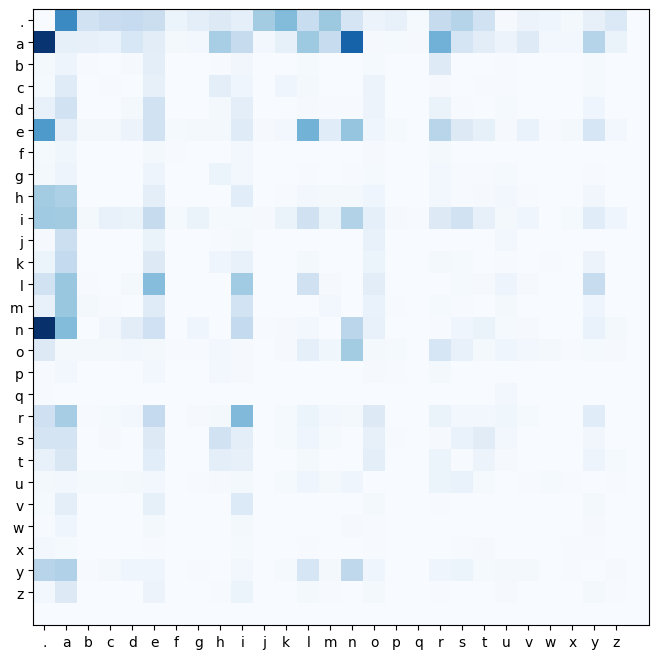

In [7]:
plt.figure(figsize=(8,8))
plt.imshow(N, cmap='Blues')
plt.xticks(range(27), [itoc[i] for i in range(27)], fontsize=10)
plt.yticks(range(27), [itoc[i] for i in range(27)], fontsize=10)
plt

In [8]:
g = torch.Generator().manual_seed(2147483647)
p = torch.rand(3, generator=g)
p = p / p.sum()
print(p)
samples = torch.multinomial(p, num_samples=10, replacement=True, generator=g)
samples

tensor([0.6064, 0.3033, 0.0903])


tensor([1, 1, 2, 0, 0, 2, 1, 1, 0, 0])

In [9]:
g = torch.Generator().manual_seed(2147483647)
p = N[0].float() # first row => charcters after '.'
p = p / p.sum()
print(p)
ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
print(ix, ": ", itoc[ix]) # character after first character

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290,
        0.0000])
10 :  j


In [10]:
P = N.float()


In [11]:
P.shape

torch.Size([28, 28])

In [12]:
print(P.sum(dim=0, keepdim=True)) # Sum of elements of column, does column wise
P.sum(dim=0, keepdim=True).shape

tensor([[32033., 33885.,  2645.,  3532.,  5496., 20423.,   905.,  1927.,  7616.,
         17701.,  2900.,  5040., 13958.,  6642., 18327.,  7934.,  1026.,   272.,
         12700.,  8106.,  5570.,  3135.,  2573.,   929.,   697.,  9776.,  2398.,
             0.]])


torch.Size([1, 28])

In [13]:
print(P.sum(dim=1, keepdim=True)) # Sum of elements of row, does row wise
P.sum(dim=1, keepdim=True).shape

tensor([[32033.],
        [33885.],
        [ 2645.],
        [ 3532.],
        [ 5496.],
        [20423.],
        [  905.],
        [ 1927.],
        [ 7616.],
        [17701.],
        [ 2900.],
        [ 5040.],
        [13958.],
        [ 6642.],
        [18327.],
        [ 7934.],
        [ 1026.],
        [  272.],
        [12700.],
        [ 8106.],
        [ 5570.],
        [ 3135.],
        [ 2573.],
        [  929.],
        [  697.],
        [ 9776.],
        [ 2398.],
        [    0.]])


torch.Size([28, 1])

In [14]:
P = N.float()
P /= P.sum(dim=1, keepdim=True) # 27x27 / 27x1 -> broadcast: 27x27 / 27x'27' 

In [15]:
for _ in range(20):
    ix = 0
    out = []
    while True:
        p = P[ix]
        # p = N[ix].float()
        # p = p / p.sum()
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itoc[ix])
        if ix == 0:
            break
    print(''.join(out))

sonde.
janasah.
p.
cony.
a.
nn.
kohin.
tolian.
juee.
ksahnaauranilevias.
dedainrwieta.
ssonielylarte.
faveumerifontume.
phynslenaruani.
core.
yaenon.
ka.
jabdinerimikimaynin.
anaasn.
ssorionsush.


In [16]:
log_likelihood = 0
n = 0
for w in words[:3]:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = ctoi[ch1]
        ix2 = ctoi[ch2]
        prob = P[ix1, ix2]
        log_prob = torch.log(prob)
        log_likelihood += log_prob
        n += 1
        print(f'{n}: {ch1}{ch2}, prob:{prob:.4f}, log prob:{log_prob:.4f}')

print(f'Log Likelihood: {log_likelihood=}')
nll = -log_likelihood
print(f'Negative Log Likelihood: {nll=}')
print(f'Normalized Negative Log Likelihood: {nll/n}')




1: .e, prob:0.0478, log prob:-3.0408
2: em, prob:0.0377, log prob:-3.2793
3: mm, prob:0.0253, log prob:-3.6772
4: ma, prob:0.3899, log prob:-0.9418
5: a., prob:0.1960, log prob:-1.6299
6: .o, prob:0.0123, log prob:-4.3982
7: ol, prob:0.0780, log prob:-2.5508
8: li, prob:0.1777, log prob:-1.7278
9: iv, prob:0.0152, log prob:-4.1867
10: vi, prob:0.3541, log prob:-1.0383
11: ia, prob:0.1381, log prob:-1.9796
12: a., prob:0.1960, log prob:-1.6299
13: .a, prob:0.1377, log prob:-1.9829
14: av, prob:0.0246, log prob:-3.7045
15: va, prob:0.2495, log prob:-1.3882
16: a., prob:0.1960, log prob:-1.6299
Log Likelihood: log_likelihood=tensor(-38.7856)
Negative Log Likelihood: nll=tensor(38.7856)
Normalized Negative Log Likelihood: 2.424102306365967


In [17]:
# Goal: maximize the likelihood of the data w.r.t model parameters
# equivalent to maximizion the log likelihood (log is monotonic)
# equivalent to minimizing the negative log likelihood
# equivalent to minimizing the average negative log likelihood

log_likelihood = 0
n = 0
for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = ctoi[ch1]
        ix2 = ctoi[ch2]
        prob = P[ix1, ix2]
        log_prob = torch.log(prob)
        log_likelihood += log_prob
        n += 1
        # print(f'{n}: {ch1}{ch2}, prob:{prob:.4f}, log prob:{log_prob:.4f}')

# likelihood of the corpus
print(f'Log Likelihood: {log_likelihood=}')
nll = -log_likelihood
print(f'Negative Log Likelihood: {nll=}')
print(f'Normalized Negative Log Likelihood: {nll/n}')

Log Likelihood: log_likelihood=tensor(-559891.7500)
Negative Log Likelihood: nll=tensor(559891.7500)
Normalized Negative Log Likelihood: 2.454094171524048


In [18]:
log_likelihood = 0
n = 0
for w in ["mahi"]:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = ctoi[ch1]
        ix2 = ctoi[ch2]
        prob = P[ix1, ix2]
        log_prob = torch.log(prob)
        log_likelihood += log_prob
        n += 1
        # print(f'{n}: {ch1}{ch2}, prob:{prob:.4f}, log prob:{log_prob:.4f}')

# likelihood of the name 'mahi'
print(f'Log Likelihood: {log_likelihood=}')
nll = -log_likelihood
print(f'Negative Log Likelihood: {nll=}')
print(f'Normalized Negative Log Likelihood: {nll/n}')

Log Likelihood: log_likelihood=tensor(-10.4615)
Negative Log Likelihood: nll=tensor(10.4615)
Normalized Negative Log Likelihood: 2.0922930240631104


In [19]:
log_likelihood = 0
n = 0
for w in ["mahijq"]:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = ctoi[ch1]
        ix2 = ctoi[ch2]
        prob = P[ix1, ix2]
        log_prob = torch.log(prob)
        log_likelihood += log_prob
        n += 1
        # print(f'{n}: {ch1}{ch2}, prob:{prob:.4f}, log prob:{log_prob:.4f}')

# likelihood of the name 'mahi'
print(f'Log Likelihood: {log_likelihood=}')
nll = -log_likelihood
print(f'Negative Log Likelihood: {nll=}')
print(f'Normalized Negative Log Likelihood: {nll/n}')
# P[j, q] = 0 => log(0) = -inf

Log Likelihood: log_likelihood=tensor(-inf)
Negative Log Likelihood: nll=tensor(inf)
Normalized Negative Log Likelihood: inf


In [20]:
# solution: smoothing
P = (N+1).float()
P /= P.sum(dim=1, keepdim=True) # 27x27 / 27x1 -> broadcast: 27x27 / 27x'27' 


log_likelihood = 0
n = 0
for w in ["mahijq"]:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = ctoi[ch1]
        ix2 = ctoi[ch2]
        prob = P[ix1, ix2]
        log_prob = torch.log(prob)
        log_likelihood += log_prob
        n += 1
        # print(f'{n}: {ch1}{ch2}, prob:{prob:.4f}, log prob:{log_prob:.4f}')

# likelihood of the name 'mahi'
print(f'Log Likelihood: {log_likelihood=}')
nll = -log_likelihood
print(f'Negative Log Likelihood: {nll=}')
print(f'Normalized Negative Log Likelihood: {nll/n}')

Log Likelihood: log_likelihood=tensor(-24.2644)
Negative Log Likelihood: nll=tensor(24.2644)
Normalized Negative Log Likelihood: 3.4663479328155518


In [21]:
# Now lets model this to neural network

'''
char -> NN -> char' -> neg_log_likelihood_loss_fn -> update params
'''

"\nchar -> NN -> char' -> neg_log_likelihood_loss_fn -> update params\n"

In [22]:
# create training set of bigrams (x, y)
xs, ys = [], []
for w in words[:1]:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        from_idx = ctoi[ch1]
        to_idx = ctoi[ch2]
        print(ch1, ch2)
        xs.append(from_idx)
        ys.append(to_idx)

xs = torch.tensor(xs)
print(xs)
ys = torch.tensor(ys)
print(ys)

. e
e m
m m
m a
a .
tensor([ 0,  5, 13, 13,  1])
tensor([ 5, 13, 13,  1,  0])


In [23]:
import torch.nn.functional as F
x_enc = F.one_hot(xs, num_classes=27).float() 
x_enc

tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [24]:
x_enc.shape

torch.Size([5, 27])

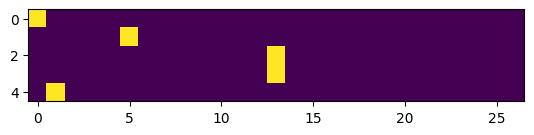

In [25]:
plt.imshow(x_enc)

In [26]:
# single neuron
W = torch.randn((27, 1))
x_enc @ W

tensor([[ 0.2613],
        [-0.0187],
        [-0.7925],
        [-0.7925],
        [ 0.3700]])

In [27]:
# randomly initialize 27 neurons' weights, each neuron receives 27 inputs
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)
x_enc @ W

tensor([[ 1.5674e+00, -2.3729e-01, -2.7385e-02, -1.1008e+00,  2.8588e-01,
         -2.9643e-02, -1.5471e+00,  6.0489e-01,  7.9136e-02,  9.0462e-01,
         -4.7125e-01,  7.8682e-01, -3.2843e-01, -4.3297e-01,  1.3729e+00,
          2.9334e+00,  1.5618e+00, -1.6261e+00,  6.7716e-01, -8.4039e-01,
          9.8488e-01, -1.4837e-01, -1.4795e+00,  4.4830e-01, -7.0730e-02,
          2.4968e+00,  2.4448e+00],
        [ 4.7236e-01,  1.4830e+00,  3.1748e-01,  1.0588e+00,  2.3982e+00,
          4.6827e-01, -6.5650e-01,  6.1662e-01, -6.2197e-01,  5.1007e-01,
          1.3563e+00,  2.3445e-01, -4.5585e-01, -1.3132e-03, -5.1161e-01,
          5.5570e-01,  4.7458e-01, -1.3867e+00,  1.6229e+00,  1.7197e-01,
          9.8846e-01,  5.0657e-01,  1.0198e+00, -1.9062e+00, -4.2753e-01,
         -2.1259e+00,  9.6041e-01],
        [ 1.9359e-01,  1.0532e+00,  6.3393e-01,  2.5786e-01,  9.6408e-01,
         -2.4855e-01,  2.4756e-02, -3.0404e-02,  1.5622e+00, -4.4852e-01,
         -1.2345e+00,  1.1220e+00, -6.73

In [28]:
(x_enc @ W).shape # 5x27 @ 27x27 = 5x27

torch.Size([5, 27])

In [29]:
(x_enc @ W)[3, 13] # firing rate of 13th neuron on seeing 3rd example

tensor(0.0379, grad_fn=<SelectBackward0>)

In [30]:
# forward pass
x_enc = F.one_hot(xs, num_classes=27).float() # input to the network: one-hot encoding
logits = x_enc @ W # predict log counts <-- modeling nn outputs as log of counts(as stored in tensor log(N))
counts = logits.exp() # elementwise exponentiation (as N)
prob = counts / counts.sum(dim=1, keepdim=True) # Probabilities of next character
# above two lines are called softmax
prob

tensor([[0.0607, 0.0100, 0.0123, 0.0042, 0.0168, 0.0123, 0.0027, 0.0232, 0.0137,
         0.0313, 0.0079, 0.0278, 0.0091, 0.0082, 0.0500, 0.2378, 0.0603, 0.0025,
         0.0249, 0.0055, 0.0339, 0.0109, 0.0029, 0.0198, 0.0118, 0.1537, 0.1459],
        [0.0290, 0.0796, 0.0248, 0.0521, 0.1989, 0.0289, 0.0094, 0.0335, 0.0097,
         0.0301, 0.0702, 0.0228, 0.0115, 0.0181, 0.0108, 0.0315, 0.0291, 0.0045,
         0.0916, 0.0215, 0.0486, 0.0300, 0.0501, 0.0027, 0.0118, 0.0022, 0.0472],
        [0.0312, 0.0737, 0.0484, 0.0333, 0.0674, 0.0200, 0.0263, 0.0249, 0.1226,
         0.0164, 0.0075, 0.0789, 0.0131, 0.0267, 0.0147, 0.0112, 0.0585, 0.0121,
         0.0650, 0.0058, 0.0208, 0.0078, 0.0133, 0.0203, 0.1204, 0.0469, 0.0126],
        [0.0312, 0.0737, 0.0484, 0.0333, 0.0674, 0.0200, 0.0263, 0.0249, 0.1226,
         0.0164, 0.0075, 0.0789, 0.0131, 0.0267, 0.0147, 0.0112, 0.0585, 0.0121,
         0.0650, 0.0058, 0.0208, 0.0078, 0.0133, 0.0203, 0.1204, 0.0469, 0.0126],
        [0.0150, 0.0086,

In [31]:
prob.shape

torch.Size([5, 27])

In [32]:
nlls = torch.zeros(5)
for i in range(5):
    # i-th bigram:
    x = xs[i].item() # input character index
    y = ys[i].item() # label character index
    print('--------')
    print(f'bigram example {i+1}: {itoc[x]}{itoc[y]} (indexes {x},{y})')
    print('input to the neural net:', x)
    print('output probabilities from the neural net:', prob[i])
    print('label (actual next character):', y)
    p = prob[i, y]
    print('probability assigned by the net to the the correct character:', p.item())
    logp = torch.log(p)
    print('log likelihood:', logp.item())
    nll = -logp
    print('negative log likelihood:', nll.item())
    nlls[i] = nll

print('==========')
print('average negative log likelihood, i.e. loss =', nlls.mean().item())


--------
bigram example 1: .e (indexes 0,5)
input to the neural net: 0
output probabilities from the neural net: tensor([0.0607, 0.0100, 0.0123, 0.0042, 0.0168, 0.0123, 0.0027, 0.0232, 0.0137,
        0.0313, 0.0079, 0.0278, 0.0091, 0.0082, 0.0500, 0.2378, 0.0603, 0.0025,
        0.0249, 0.0055, 0.0339, 0.0109, 0.0029, 0.0198, 0.0118, 0.1537, 0.1459],
       grad_fn=<SelectBackward0>)
label (actual next character): 5
probability assigned by the net to the the correct character: 0.01228625513613224
log likelihood: -4.399273872375488
negative log likelihood: 4.399273872375488
--------
bigram example 2: em (indexes 5,13)
input to the neural net: 5
output probabilities from the neural net: tensor([0.0290, 0.0796, 0.0248, 0.0521, 0.1989, 0.0289, 0.0094, 0.0335, 0.0097,
        0.0301, 0.0702, 0.0228, 0.0115, 0.0181, 0.0108, 0.0315, 0.0291, 0.0045,
        0.0916, 0.0215, 0.0486, 0.0300, 0.0501, 0.0027, 0.0118, 0.0022, 0.0472],
       grad_fn=<SelectBackward0>)
label (actual next character):

In [33]:
ys

tensor([ 5, 13, 13,  1,  0])

In [34]:
# we want this probs
prob[0, 5],prob[1, 13],prob[2, 13],prob[3, 1],prob[4, 0]

(tensor(0.0123, grad_fn=<SelectBackward0>),
 tensor(0.0181, grad_fn=<SelectBackward0>),
 tensor(0.0267, grad_fn=<SelectBackward0>),
 tensor(0.0737, grad_fn=<SelectBackward0>),
 tensor(0.0150, grad_fn=<SelectBackward0>))

In [35]:
# loss calculation
# prob[torch.arange(5), ys] # prob of currect next character assigned by NN
loss = -prob[torch.arange(5), ys].log().mean() # nll 
loss

tensor(3.7693, grad_fn=<NegBackward0>)

In [36]:
# backward pass
W.grad = None
print(loss.item)
loss.backward()
W.data += -0.01 * W.grad

<built-in method item of Tensor object at 0x000001BC2AEA7C50>


In [37]:
W.shape, W.grad.shape

(torch.Size([27, 27]), torch.Size([27, 27]))

In [38]:
axs, ays = [], []
for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        from_idx = ctoi[ch1]
        to_idx = ctoi[ch2]
        axs.append(from_idx)
        ays.append(to_idx)

axs = torch.tensor(axs)
ays = torch.tensor(ays)
num = axs.nelement()

ax_enc = F.one_hot(axs, num_classes=27).float() # input to the network: one-hot encoding

In [39]:
g = torch.Generator().manual_seed(2147483647)

In [40]:
nW = torch.randn((27, 27), generator=g, requires_grad=True)
eta, beta = 50, 0.01
for k in range(100):
    # forward pass
    nlogits = ax_enc @ nW # predict log counts <-- modeling nn outputs as log of counts(as stored in tensor log(N))
    ncounts = nlogits.exp() # elementwise exponentiation (as N)
    nprob = ncounts / ncounts.sum(dim=1, keepdim=True) # Probabilities of next character
    # above two lines are called softmax
    # nloss = -nprob[torch.arange(num), ays].log().mean() # nll 
    nloss = -nprob[torch.arange(num), ays].log().mean() + beta * (nW**2).mean() # regularization: try to keep nW near 0 -> this will try pull weights near 0 and make distribution uniform
    print(nloss.item())

    # backward pass
    nW.grad = None
    nloss.backward()
    # update weights
    nW.data += -eta * nW.grad


3.7686190605163574
3.3788068294525146
3.161090850830078
3.027186155319214
2.9344842433929443
2.8672313690185547
2.816654682159424
2.777146577835083
2.745253801345825
2.7188303470611572
2.696505546569824
2.6773719787597656
2.6608052253723145
2.6463515758514404
2.633665084838867
2.622471570968628
2.6125476360321045
2.6037068367004395
2.595794916152954
2.5886809825897217
2.582256317138672
2.5764293670654297
2.5711238384246826
2.566272735595703
2.5618226528167725
2.5577263832092285
2.5539445877075195
2.550442695617676
2.5471925735473633
2.5441696643829346
2.5413525104522705
2.538722038269043
2.536262035369873
2.5339581966400146
2.531797409057617
2.5297679901123047
2.527860164642334
2.5260636806488037
2.5243709087371826
2.522773265838623
2.521263837814331
2.519836664199829
2.5184857845306396
2.517204999923706
2.515990734100342
2.5148372650146484
2.5137410163879395
2.512697696685791
2.511704921722412
2.5107581615448
2.509854793548584
2.5089924335479736
2.5081686973571777
2.507380247116089
2.

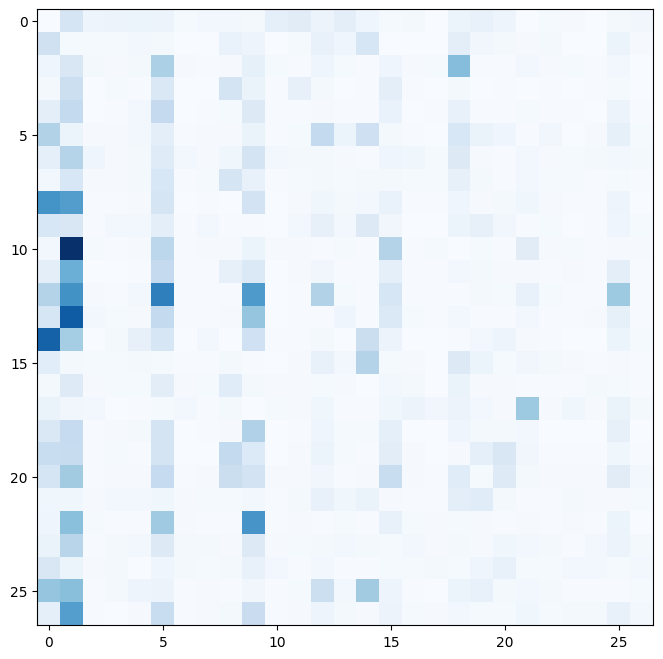

In [41]:
plt.figure(figsize=(8,8))
plt.imshow(nW.exp().detach().numpy(), cmap='Blues')
# W is literally a log(N)

In [42]:
for _ in range(20):
    ix = 0
    out = []
    while True:
        # p = P[ix]
        x_enc = F.one_hot(torch.tensor([ix]), num_classes=27).float()
        logits = x_enc @ nW
        counts = logits.exp()
        p = counts / counts.sum(dim=1, keepdim=True)
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itoc[ix])
        if ix == 0:
            break
    print(''.join(out))

morvann.
akela.
az.
arileri.
chaiadayra.
fbrlqwouseyton.
za.
sabran.
han.
ke.
etamete.
conakin.
lalastan.
tcyonanisemyn.
lewlixin.
kadarekan.
ljagkin.
mfian.
kicnaylula.
jvy.


In [43]:
# Now lets use MLP